**SAPIANS** · SCC5819 · MÓDULO 08 — INTERAÇÃO · MOLNAR, CAP. 21

# H por dentro — verificar resíduo, escala e degeneração

O ALE descreveu diferenças locais; o walkthrough de interação voltou às
dependências parciais para medir um resíduo aditivo. Este caderno confere H
em funções conhecidas e na mesma referência usada pela aplicação.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/08-feature-interaction/notebooks/interaction_internals.ipynb)

---

**Objetivos.** Distinguir os controles aditivo, multiplicativo e constante;
conferir o efeito da transformação de escala; reconstruir H e comparar sua
fórmula com a tradução de iml, preservando o tratamento do denominador.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Aditividade, produto e denominador degenerado

Aplicamos a definição a funções conhecidas. Um produto simétrico tem apenas interação; uma função aditiva não tem resíduo. Uma função constante torna a razão indefinida.

In [4]:
# Referência controlada: grade cartesiana balanceada, sem relação com pacientes.
u = np.linspace(-1, 1, 9)
sintetico = pd.DataFrame(itertools.product(u, u), columns=["a", "b"])


def aditiva(d):
    return 2 + np.exp(d["a"].to_numpy()) - d["b"].to_numpy()


def multiplicativa(d):
    return d["a"].to_numpy() * d["b"].to_numpy()


print("Pontos sintéticos:", SP.pt_int(len(sintetico)))

r_add = G.h_par(aditiva, sintetico, sintetico, ("a", "b"))
r_prod = G.h_par(multiplicativa, sintetico, sintetico, ("a", "b"))
r_const = G.h_par(lambda d: np.ones(len(d)), sintetico, sintetico, ("a", "b"))
assert r_add["h"] < 1e-12 and np.isclose(r_prod["h"], 1)
assert np.isnan(r_const["h"])
print("H aditivo:", SP.pt(r_add["h"], 8))
print("H do produto:", SP.pt(r_prod["h"], 8))
print("H constante indefinido:", np.isnan(r_const["h"]))
# Recalcula o caso real com um laço independente da pd_empirica.
av = xp.iloc[:32]
par = ("idade_anos", "saturacao")


def pd_laco(cols):
    out = []
    for row in av[list(cols)].itertuples(index=False, name=None):
        z = xf.copy(deep=True)
        for col, value in zip(cols, row):
            if isinstance(z[col].dtype, pd.CategoricalDtype):
                z[col] = pd.Categorical([value] * len(z), dtype=xf[col].dtype)
            else:
                z[col] = pd.Series(value, index=z.index, dtype=xf[col].dtype)
        out.append(prever(z).mean())
    out = np.asarray(out)
    return out - out.mean()


a, b, joint = pd_laco([par[0]]), pd_laco([par[1]]), pd_laco(par)
h2 = np.sum((joint - a - b) ** 2) / np.sum(joint**2)
r = G.h_par(prever, xf, av, par)
assert np.isclose(h2, r["h2"], atol=1e-12)
print("H² real pelo laço independente:", SP.pt(h2, 8))
print("Erro H² entre implementações:", SP.pt_sig(abs(h2 - r["h2"]), 4))

Pontos sintéticos: 81
H aditivo: 0,00000000
H do produto: 1,00000000
H constante indefinido: True


H² real pelo laço independente: 0,01937000
Erro H² entre implementações: 0,0000


**O que olhar.**

- Os controles distinguem ausência de resíduo e ausência de denominador.
- A reconstrução real usa as mesmas fichas e compara a fórmula, sem depender de uma biblioteca externa de H.

## §3 — A transformação de escala cria não aditividade

Um escore aditivo deixa de ser aditivo após uma transformação logística. Comparamos o mesmo mecanismo nas escalas de escore e probabilidade; portanto H exige declarar a saída explicada.

H no escore aditivo: 0,00000000
H após logística: 0,22465572
figura: figures_generated/interaction-escala.png


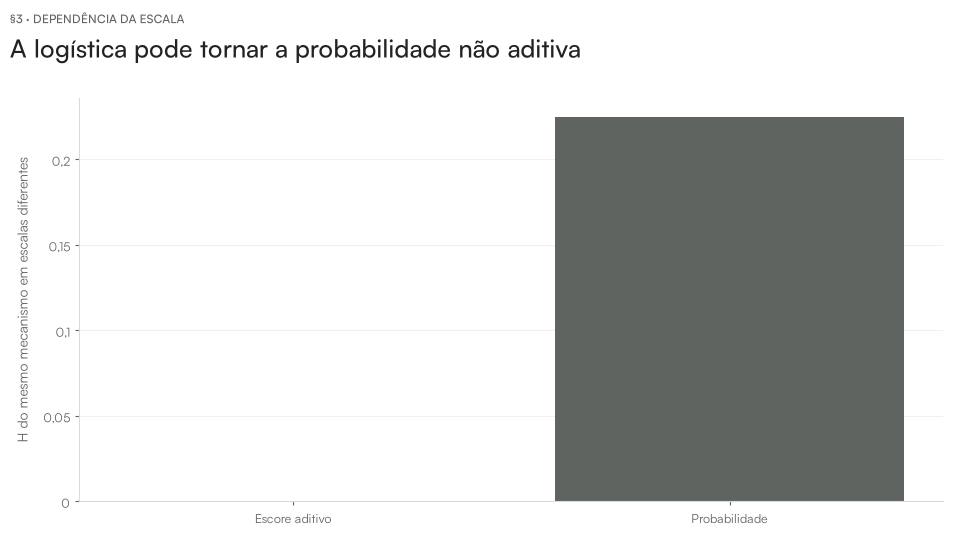

In [5]:
from scipy.special import expit


def escore(d):
    return 1.5 * d["a"].to_numpy() + 2 * d["b"].to_numpy() + 1


def probabilidade(d):
    return expit(escore(d))


he = G.h_par(escore, sintetico, sintetico, ("a", "b"))
hp = G.h_par(probabilidade, sintetico, sintetico, ("a", "b"))
assert he["h"] < 1e-12 and hp["h"] > 0
print("H no escore aditivo:", SP.pt(he["h"], 8))
print("H após logística:", SP.pt(hp["h"], 8))
fig, ax = plt.subplots(figsize=SP.SLOT)
ax.bar(
    ["Escore aditivo", "Probabilidade"], [he["h"], hp["h"]], color=[SP.ESCURO, SP.CINZA]
)
ax.set(ylabel="H do mesmo mecanismo em escalas diferentes")
SP.titulo(
    fig,
    "A logística pode tornar a probabilidade não aditiva",
    "§3 · Dependência da escala",
)
SP.salvar(fig, "interaction-escala")
plt.show()

**O que olhar.**

- A mudança de H é produzida pela escala, sem um novo ajuste.
- H em probabilidade não demonstra que existia um termo de interação no escore linear.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/interaction.html)
constrói H a partir de dependências parciais centralizadas. Os controles deste
caderno distinguem ausência de resíduo de ausência de variação para normalizar.
A transformação logística mostra por que declarar a escala é necessário.

A tradução de `h.test` confere a fórmula sob as mesmas previsões. Ela não
reproduz nativamente o pacote R nem elimina diferenças de orçamento entre o
fundo e os pontos avaliados. A concordância algébrica sustenta o diagnóstico
do preditor; não demonstra uma interação clínica.

## §4 — Confronto com h.test de iml

A função `h.test` centraliza as dependências parciais e calcula a raiz da razão de somas de quadrados. Traduzimos esse trecho literalmente sobre as mesmas previsões já conferidas pelo laço independente. Média ou soma se cancelam na razão. O nosso núcleo acrescenta uma tolerância explícita para denominadores quase nulos e preserva a razão indefinida.

No pacote, `grid.size` sorteia os pontos avaliados e o conjunto do Predictor fornece o fundo. Nossa aplicação separa esses orçamentos. A concordância da fórmula não transforma a escolha de amostras numa réplica integral da configuração dos exemplos.


In [6]:
def h_test_iml_traduzido(f_all, f_j, f_no_j):
    all_c, j_c, no_c = [np.asarray(v) - np.mean(v) for v in (f_all, f_j, f_no_j)]
    return np.sqrt(np.sum((all_c - (j_c + no_c)) ** 2) / np.sum(all_c**2))


h_iml = h_test_iml_traduzido(joint, a, b)
assert np.isclose(h_iml, r["h"], atol=1e-12)
print("H pelo h.test traduzido:", SP.pt(h_iml, 8))
print("Erro H vs h.test traduzido:", SP.pt_sig(abs(h_iml - r["h"]), 4))
print("Tolerância absoluta para o denominador:", SP.pt_sig(1e-14, 2))
print("Zero de variância não implica aditividade:", np.isnan(r_const["h"]))

H pelo h.test traduzido: 0,13917614
Erro H vs h.test traduzido: 0,0000
Tolerância absoluta para o denominador: 1,00×10⁻¹⁴
Zero de variância não implica aditividade: True


## Fechamento — zero de resíduo e razão indefinida são distintos

- O controle aditivo examina o resíduo; a função constante verifica a falta de
  denominador. A degeneração permanece explícita, em vez de virar ausência
  de interação.
- Transformar um escore muda sua aditividade sem novo ajuste. H em probabilidade
  não é uma declaração sobre termos de interação no escore original.
- A conferência com iml fixa as previsões e a centralização. O tratamento de
  denominadores quase nulos e a separação dos orçamentos continuam declarados.

In [7]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 21](https://christophm.github.io/interpretable-ml-book/interaction.html). Referências completas e configuração no [README](../README.md).